## Training of the alternative classifier on the 3rd level

In [ ]:
import os
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras import layers, losses, optimizers, models, metrics, callbacks
from keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
from tensorflow.keras.utils import register_keras_serializable
import keras_tuner
from keras_tuner import RandomSearch, Hyperband, BayesianOptimization

In [ ]:
current_dir = Path.cwd()

In [ ]:
desc_dim = 887
emb_dim = 1024
batch_size = 32
epoch = 100
dtype = tf.float32
model_e_dir = str(current_dir.parent / 'models/untrained_model.keras')

In [3]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()
tf.keras.mixed_precision.set_global_policy('float64')

In [4]:
def reset_weigths(model: models.Model):
    for layer in model.layers:
        if hasattr(layer, 'kernel_initializer'):
            layer.kernel.assign(layer.kernel_initializer(shape=layer.kernel.shape, dtype=layer.kernel.dtype))
        if hasattr(layer, 'bias_initializer') and layer.use_bias:
            layer.bias.assign(layer.bias_initializer(shape=layer.bias.shape, dtype=layer.bias.dtype))
        if hasattr(layer, 'moving_mean'):
            layer.moving_mean.assign(tf.zeros_like(layer.moving_mean))
        if hasattr(layer, 'moving_variance'):
            layer.moving_variance.assign(tf.ones_like(layer.moving_variance))
def load_untrained_model(model_dir):
    model = models.load_model(str(model_dir))
    reset_weigths(model)
    return model

In [ ]:
train = pd.read_csv(str(current_dir.parent / 'datasets/train_vae.csv'))
valid = pd.read_csv(str(current_dir.parent / 'datasets/valid_vae.csv'))
test = pd.read_csv(str(current_dir.parent / 'datasets/test_vae.csv'))
train_t = np.load(str(current_dir.parent / 'datasets/train_embeddings.npy'))
valid_t = np.load(str(current_dir.parent / 'datasets/valid_embeddings.npy'))
test_t = np.load(str(current_dir.parent / 'datasets/test_embeddings.npy'))

In [6]:
train_f = (train.iloc[:,5:-1].copy()).to_numpy()
valid_f = (valid.iloc[:,5:-1].copy()).to_numpy()
test_f = (test.iloc[:,3:-1].copy()).to_numpy()
y = (test.iloc[:,-1].copy()).to_numpy()
y_top = np.zeros(shape=(len(train_t) + len(valid_t),))
y = np.concatenate([y_top, y])
X_emb = np.vstack((train_t, valid_t, test_t))
X_feat = np.vstack((train_f, valid_f, test_f))
s_scaler_t = StandardScaler()
s_scaler_f = StandardScaler()
X_emb = s_scaler_t.fit_transform(X_emb)
X_feat = s_scaler_f.fit_transform(X_feat)
X = np.concatenate([X_emb, X_feat], axis=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42, stratify=y_test)
X_train_emb = X_train[:,:1024].copy()
X_train_feat = X_train[:,1024:].copy()
X_valid_emb = X_valid[:,:1024].copy()
X_valid_feat = X_valid[:,1024:].copy()
X_test_emb = X_test[:,:1024].copy()
X_test_feat = X_test[:,1024:].copy()

In [7]:
train_d = tf.data.Dataset.from_tensor_slices(
    ((X_train_emb.astype('float32'), X_train_feat.astype('float32')), y_train.reshape((-1, 1)))
).batch(batch_size)
valid_d = tf.data.Dataset.from_tensor_slices(
    ((X_valid_emb.astype('float32'), X_valid_feat.astype('float32')), y_valid.reshape((-1, 1)))
).batch(batch_size)

In [8]:
model: models.Model = load_untrained_model(model_e_dir)
model.summary()

c:\Users\Victor\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 46 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "classifier_3l"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 1024)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise_2    │ (None, 1024)      │          0 │ input_layer_3[0]… │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 640)       │    656,000 │ gaussian_noise_2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 640)       │      2,560 │ dense_7[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 640)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 640)       │          0 │ activation_7[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 320)       │    205,120 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 320)       │      1,280 │ dense_8[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 320)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 887)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 320)       │          0 │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise_3    │ (None, 887)       │          0 │ input_layer_2[0]… │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 160)       │     51,360 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 512)       │    454,656 │ gaussian_noise_3… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160)       │        640 │ dense_9[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense_10[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 160)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 512)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 160)       │          0 │ activation_9[0][

 Total params: 4,244,389 (16.19 MB)

 Trainable params: 1,413,665 (5.39 MB)

 Non-trainable params: 3,392 (13.25 KB)

 Optimizer params: 2,827,332 (10.79 MB)

In [9]:
def build_model(hp) -> keras.Model:
    input_desc = layers.Input(shape=(desc_dim,), dtype=dtype)
    input_emb = layers.Input(shape=(emb_dim,), dtype=dtype)
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    activation = hp.Choice('activation', values=['relu', 'swish', 'leaky_relu', 'elu'])
    l2_reg = hp.Float('l2_reg', min_value=1e-5, max_value=1e-2, sampling='log')
    noise_std = hp.Float('noise_std', min_value=0.01, max_value=0.1, step=0.03)

    noisy_emb = layers.GaussianNoise(noise_std)(input_emb)
    noisy_desc = layers.GaussianNoise(noise_std)(input_desc)

    #y = input_emb
    y = noisy_emb
    units_e = hp.Int(f'emb_units_start', min_value=256, max_value=768, step=64)
    for i in range(hp.Int('emb_layers', 1, 3)):
        y = layers.Dense(units_e // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(y)
        y = layers.BatchNormalization()(y)
        y = layers.Activation(activation)(y)
        y = layers.Dropout(dropout_rate)(y)

    #x = input_desc
    x = noisy_desc
    units_d = hp.Int(f'desc_units_start', min_value=128, max_value=512, step=64)
    for i in range(hp.Int('desc_layers', 1, 3)):
        x = layers.Dense(units_d // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation(activation)(x)
        x = layers.Dropout(dropout_rate)(x)

    combined = layers.Concatenate()([y, x])
    
    z = combined
    units_h = hp.Int(f'head_units_start', min_value=64, max_value=256, step=64)
    num_layers = hp.Int('head_layers', 1, 3)
    for i in range(num_layers):
        z = layers.Dense(units_h // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(z)
        z = layers.BatchNormalization()(z)
        z = layers.Activation(activation)(z)
        if i + 1 != num_layers:
            z = layers.Dropout(dropout_rate)(z)

    z = layers.Dense(1)(z)
    output = layers.Activation('sigmoid')(z)
    model = models.Model([input_emb, input_desc], output, name='classifier_3l')
    learning_rate = hp.Float('learning_rate', min_value=1e-6, max_value=1e-3, sampling='log')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=[metrics.AUC(curve='ROC', multi_label=True), metrics.F1Score(average='macro')]
    )
    return model

tuner = Hyperband(
        build_model,
        objective = "val_loss",
        max_epochs=50,
        factor=3,
        seed=42,
        directory='tunning_TL',
        project_name='enzyme_dual_branch'
    )
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best Hyperparameters:")
lr = 0.0001
for param in best_hp.values:
    print(f"{param}: {best_hp.get(param)}")
    if param == 'learning_rate':
        lr = best_hp.get(param)

Reloading Tuner from tunning_TL\enzyme_dual_branch\tuner0.json
Best Hyperparameters:
dropout_rate: 0.30000000000000004
activation: swish
l2_reg: 1.6308979287756596e-05
noise_std: 0.01
emb_units_start: 640
emb_layers: 3
desc_units_start: 512
desc_layers: 1
head_units_start: 64
head_layers: 1
learning_rate: 0.00037947689254228217
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0046


#### Training process

In [ ]:
from typing import Any

@register_keras_serializable()
class BinaryF1Score(metrics.Metric):
    def __init__(self, name='f1_score', threshold=0.5, dtype=tf.float32, **kwargs):
        super().__init__(name=name, dtype=dtype, **kwargs)
        self.threshold = threshold
        self.true_positives = self.add_weight(name='true_positives', initializer='zeros')
        self.false_positives = self.add_weight(name='false_positives', initializer='zeros')
        self.false_negatives = self.add_weight(name='false_negatives', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(tf.reshape(y_true, (-1,)), self.dtype)
        y_pred = tf.cast(tf.reshape(y_pred, (-1,)), self.dtype)
        y_pred = tf.cast(y_pred >= self.threshold, self.dtype)

        if sample_weight is not None:
            sample_weight = tf.cast(tf.reshape(sample_weight, (-1,)), self.dtype)
        else:
            sample_weight = tf.ones_like(y_true, dtype=self.dtype)

        true_positives = tf.reduce_sum(sample_weight * y_true * y_pred)
        false_positives = tf.reduce_sum(sample_weight * (1.0 - y_true) * y_pred)
        false_negatives = tf.reduce_sum(sample_weight * y_true * (1.0 - y_pred))

        self.true_positives.assign_add(true_positives)
        self.false_positives.assign_add(false_positives)
        self.false_negatives.assign_add(false_negatives)

    def result(self):
        numerator = 2.0 * self.true_positives
        denominator = numerator + self.false_positives + self.false_negatives
        return tf.math.divide_no_nan(numerator, denominator)

    def reset_state(self):
        self.true_positives.assign(0.0)
        self.false_positives.assign(0.0)
        self.false_negatives.assign(0.0)

    def get_config(self):
        config = super().get_config()
        config.update({'threshold': self.threshold})
        return config

class Classifier(keras.Model):
    def __init__(self, model: keras.Model, loss, **kwargs: Any) -> None:
        super(Classifier, self).__init__(**kwargs)
        self.model = model
        self.current_loss = loss
        self.total_loss_tracker = metrics.Mean(name="loss")
        self.f1_tracker = BinaryF1Score()
    
    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.f1_tracker
        ]
    
    def call(self, inputs) -> Any:
        return self.model(inputs)
    
    def train_step(self, data):
        X, y = data
        with tf.GradientTape() as tape:
            pred = self(X)
            loss = self.current_loss(y, pred)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.total_loss_tracker.update_state(loss)
        self.f1_tracker.update_state(y, pred)
        return {m.name: m.result() for m in self.metrics}
    
    def test_step(self, data):
        X, y = data
        pred = self(X)
        loss = self.current_loss(y, pred)
        self.total_loss_tracker.update_state(loss)
        self.f1_tracker.update_state(y, pred)
        return {m.name: m.result() for m in self.metrics}

def train(train_data: tf.data.Dataset, valid_data: tf.data.Dataset, model: models.Model) -> None:
    optimizer = optimizers.Adam(lr, clipnorm=1.0)
    loss = losses.binary_crossentropy
    ea = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )
    logger = callbacks.CSVLogger(str(current_dir.parent / 'notebooks/history_3l_classifier.csv'))
    """
    rlr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', 
        factor=0.5,
        patience=3, 
        min_lr=1e-6,
        verbose=1
    )
    """
    classifier = Classifier(model, loss)
    classifier.compile(optimizer)
    classifier.fit(train_data, batch_size=batch_size, epochs=epoch, callbacks=[ea, logger], validation_data=valid_data)
    classifier.model.save(str(current_dir.parent / 'models/dual_classifier_model.keras'))
    print('Training process completed')

In [11]:
train(train_d, valid_d, model)

Epoch 1/100


770/770 ━━━━━━━━━━━━━━━━━━━━ 29s 29ms/step - f1_score: 0.7771 - loss: 0.0289 - val_f1_score: 0.8605 - val_loss: 0.0172
Epoch 2/100
770/770 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - f1_score: 0.9372 - loss: 0.0096 - val_f1_score: 0.8431 - val_loss: 0.0192
Epoch 3/100
770/770 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - f1_score: 0.9583 - loss: 0.0075 - val_f1_score: 0.9072 - val_loss: 0.0124
Epoch 4/100
770/770 ━━━━━━━━━━━━━━━━━━━━ 22s 29ms/step - f1_score: 0.9738 - loss: 0.0037 - val_f1_score: 0.9149 - val_loss: 0.0071
Epoch 5/100
770/770 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - f1_score: 0.9780 - loss: 0.0037 - val_f1_score: 0.9149 - val_loss: 0.0106
Epoch 6/100
770/770 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - f1_score: 0.9808 - loss: 0.0024 - val_f1_score: 0.9247 - val_loss: 0.0156
Epoch 7/100
770/770 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - f1_score: 0.9849 - loss: 0.0027 - val_f1_score: 0.9362 - val_loss: 0.0195
Epoch 8/100
770/770 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - f1_score: 0.9768 - loss: 0.0045 - val_

In [ ]:
model: models.Model = models.load_model(str(current_dir.parent / 'models/dual_classifier_model.keras'))

In [12]:
pred_train = model.predict((X_train_emb, X_train_feat))
pred_valid = model.predict((X_valid_emb, X_valid_feat))
pred_train = (pred_train > 0.5).astype(int)
pred_valid = (pred_valid > 0.5).astype(int)

770/770 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


In [13]:
y_train = y_train.reshape((-1, 1))
y_valid = y_valid.reshape((-1, 1))

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

Accuracy training: 0.9995
Accuracy test: 0.9974
Precision training: 0.9758
Precision test: 0.8958
Recall training: 0.9891
Recall test: 0.9348
AUC training: 0.9944
AUC test: 0.9666
F1-score training: 0.9824
F1-score test: 0.9149
Clasification report training:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     24263
         1.0       0.98      0.99      0.98       367

    accuracy                           1.00     24630
   macro avg       0.99      0.99      0.99     24630
weighted avg       1.00      1.00      1.00     24630

Clasification report test:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      3033
         1.0       0.90      0.93      0.91        46

    accuracy                           1.00      3079
   macro avg       0.95      0.97      0.96      3079
weighted avg       1.00      1.00      1.00      3079



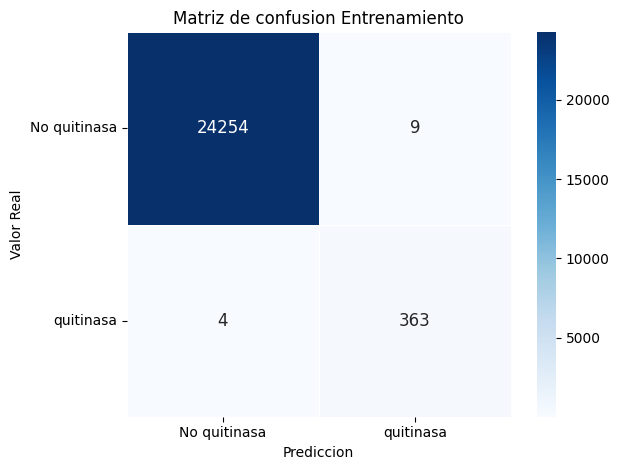

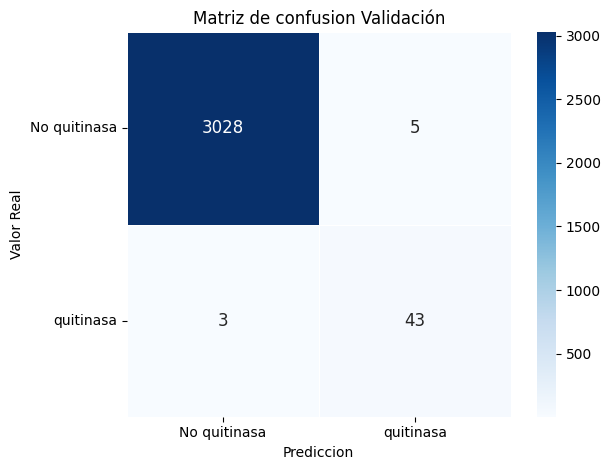

In [15]:
accuracy_t = accuracy_score(y_train, pred_train)
accuracy_v = accuracy_score(y_valid, pred_valid)
precision_t = precision_score(y_train, pred_train)
precision_v = precision_score(y_valid, pred_valid)
recall_t = recall_score(y_train, pred_train)
recall_v = recall_score(y_valid, pred_valid)
roc_auc_t = roc_auc_score(y_train, pred_train)
roc_auc_v = roc_auc_score(y_valid, pred_valid)
f1_t = f1_score(y_train, pred_train)
f1_v = f1_score(y_valid, pred_valid)
conf_matrix_t = confusion_matrix(y_train, pred_train)
conf_matrix_v = confusion_matrix(y_valid, pred_valid)
print(f"Accuracy training: {accuracy_t:.4f}")
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision training: {precision_t:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall training: {recall_t:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC training: {roc_auc_t:.4f}')
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score training: {f1_t:.4f}")
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report training:", classification_report(y_train, pred_train), sep=f'\n')
print("Clasification report test:", classification_report(y_valid, pred_valid), sep=f'\n')
class_labels = ['No quitinasa', 'quitinasa']
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Entrenamiento')
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Validación')

97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
F1-score test: 0.9574
Clasification report test:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      3033
         1.0       0.94      0.98      0.96        46

    accuracy                           1.00      3079
   macro avg       0.97      0.99      0.98      3079
weighted avg       1.00      1.00      1.00      3079



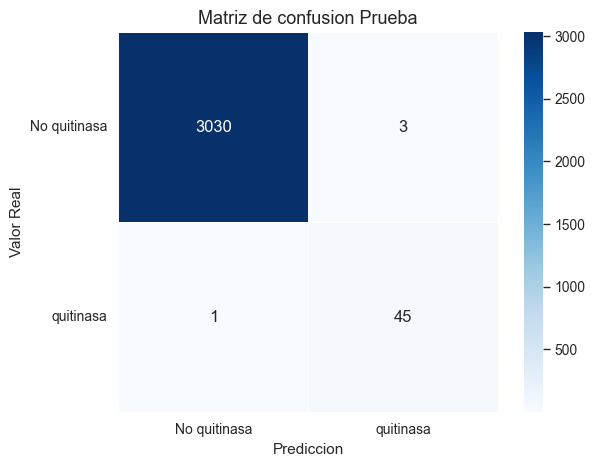

In [20]:
pred_test = model.predict((X_test_emb, X_test_feat))
pred_test = (pred_test > 0.5).astype(int)
y_test = y_test.reshape((-1, 1))
f1_t = f1_score(y_test, pred_test)
conf_matrix_t = confusion_matrix(y_test, pred_test)
print(f"F1-score test: {f1_t:.4f}")
print("Clasification report test:", classification_report(y_test, pred_test), sep=f'\n')
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Prueba')

In [ ]:
history = pd.read_csv(str(current_dir.parent / 'notebooks/history_3l_classifier.csv'))
history.head(10)

,epoch,f1_score,loss,val_f1_score,val_loss
0,0,0.777126,0.028923,0.860465,0.017180
1,1,0.937239,0.009602,0.843137,0.019222
2,2,0.958333,0.007505,0.907216,0.012361
3,3,0.973793,0.003672,0.914894,0.007142
4,4,0.977961,0.003704,0.914894,0.010558
5,5,0.980822,0.002416,0.924731,0.015570
6,6,0.984911,0.002659,0.936170,0.019525
7,7,0.976808,0.004457,0.896552,0.019595
8,8,0.991826,0.001231,0.936170,0.017552


In [16]:
from matplotlib.ticker import MaxNLocator
def plot_charts(history: pd.DataFrame, metrics: tuple[str, str], labels: tuple[str, str]):
    epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

    best_val_loss_idx = history[f'val_{metrics[0]}'].idxmin()
    best_val_acc_idx = history[f'val_{metrics[1]}'].idxmax()

    train_color = '#1f77b4'
    valid_color = '#d62728'
    highlight_color = '#222222'

    sns.set_theme(style='whitegrid', context='paper')
    plt.rcParams.update({
        'font.size': 11,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

    metric_specs = [
        {
            'ax': axes[0],
            'train_key': metrics[0],
            'valid_key': f'val_{metrics[0]}',
            'title': f'{labels[0]} del entrenamiento y validación',
            'ylabel': labels[0],
            'best_idx': best_val_loss_idx,
        },
        {
            'ax': axes[1],
            'train_key': metrics[1],
            'valid_key': f'val_{metrics[1]}',
            'title': f'{labels[1]} del entrenamiento y validación',
            'ylabel': labels[1],
            'best_idx': best_val_acc_idx,
        },
    ]

    for spec in metric_specs:
        ax = spec['ax']
        train_values = history[spec['train_key']].to_numpy()
        valid_values = history[spec['valid_key']].to_numpy()
        best_epoch = int(epochs[spec['best_idx']])
        best_value = valid_values[spec['best_idx']]

        ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
        ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
        ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
        ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
        '''
        ax.annotate(
            f"Época {best_epoch}\n{best_value:.4f}",
            xy=(best_epoch, best_value),
            xytext=(10, 12),
            textcoords='offset points',
            fontsize=9,
            color=highlight_color,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
            arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
        )
        '''

        ax.set_title(spec['title'], pad=10, weight='bold')
        ax.set_xlabel('Época')
        ax.set_ylabel(spec['ylabel'])
        ax.set_xlim(epochs.min(), epochs.max())
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
        ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
        ax.minorticks_on()
        ax.tick_params(axis='both', which='major', length=5, width=0.8)
        ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

    axes[0].text(
        0.02,
        0.98,
        f"{labels[0]} final del entrenamiento: {history[metrics[0]].iloc[-1]:.4f}\n{labels[0]} final validación: {history[f'val_{metrics[0]}'].iloc[-1]:.4f}",
        transform=axes[0].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    axes[1].text(
        0.02,
        0.98,
        f"{labels[1]} final entrenamiento: {history[metrics[1]].iloc[-1]:.4f}\n{labels[1]} final validación: {history[f'val_{metrics[1]}'].iloc[-1]:.4f}",
        transform=axes[1].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
    sns.despine(fig=fig)
    plt.show()

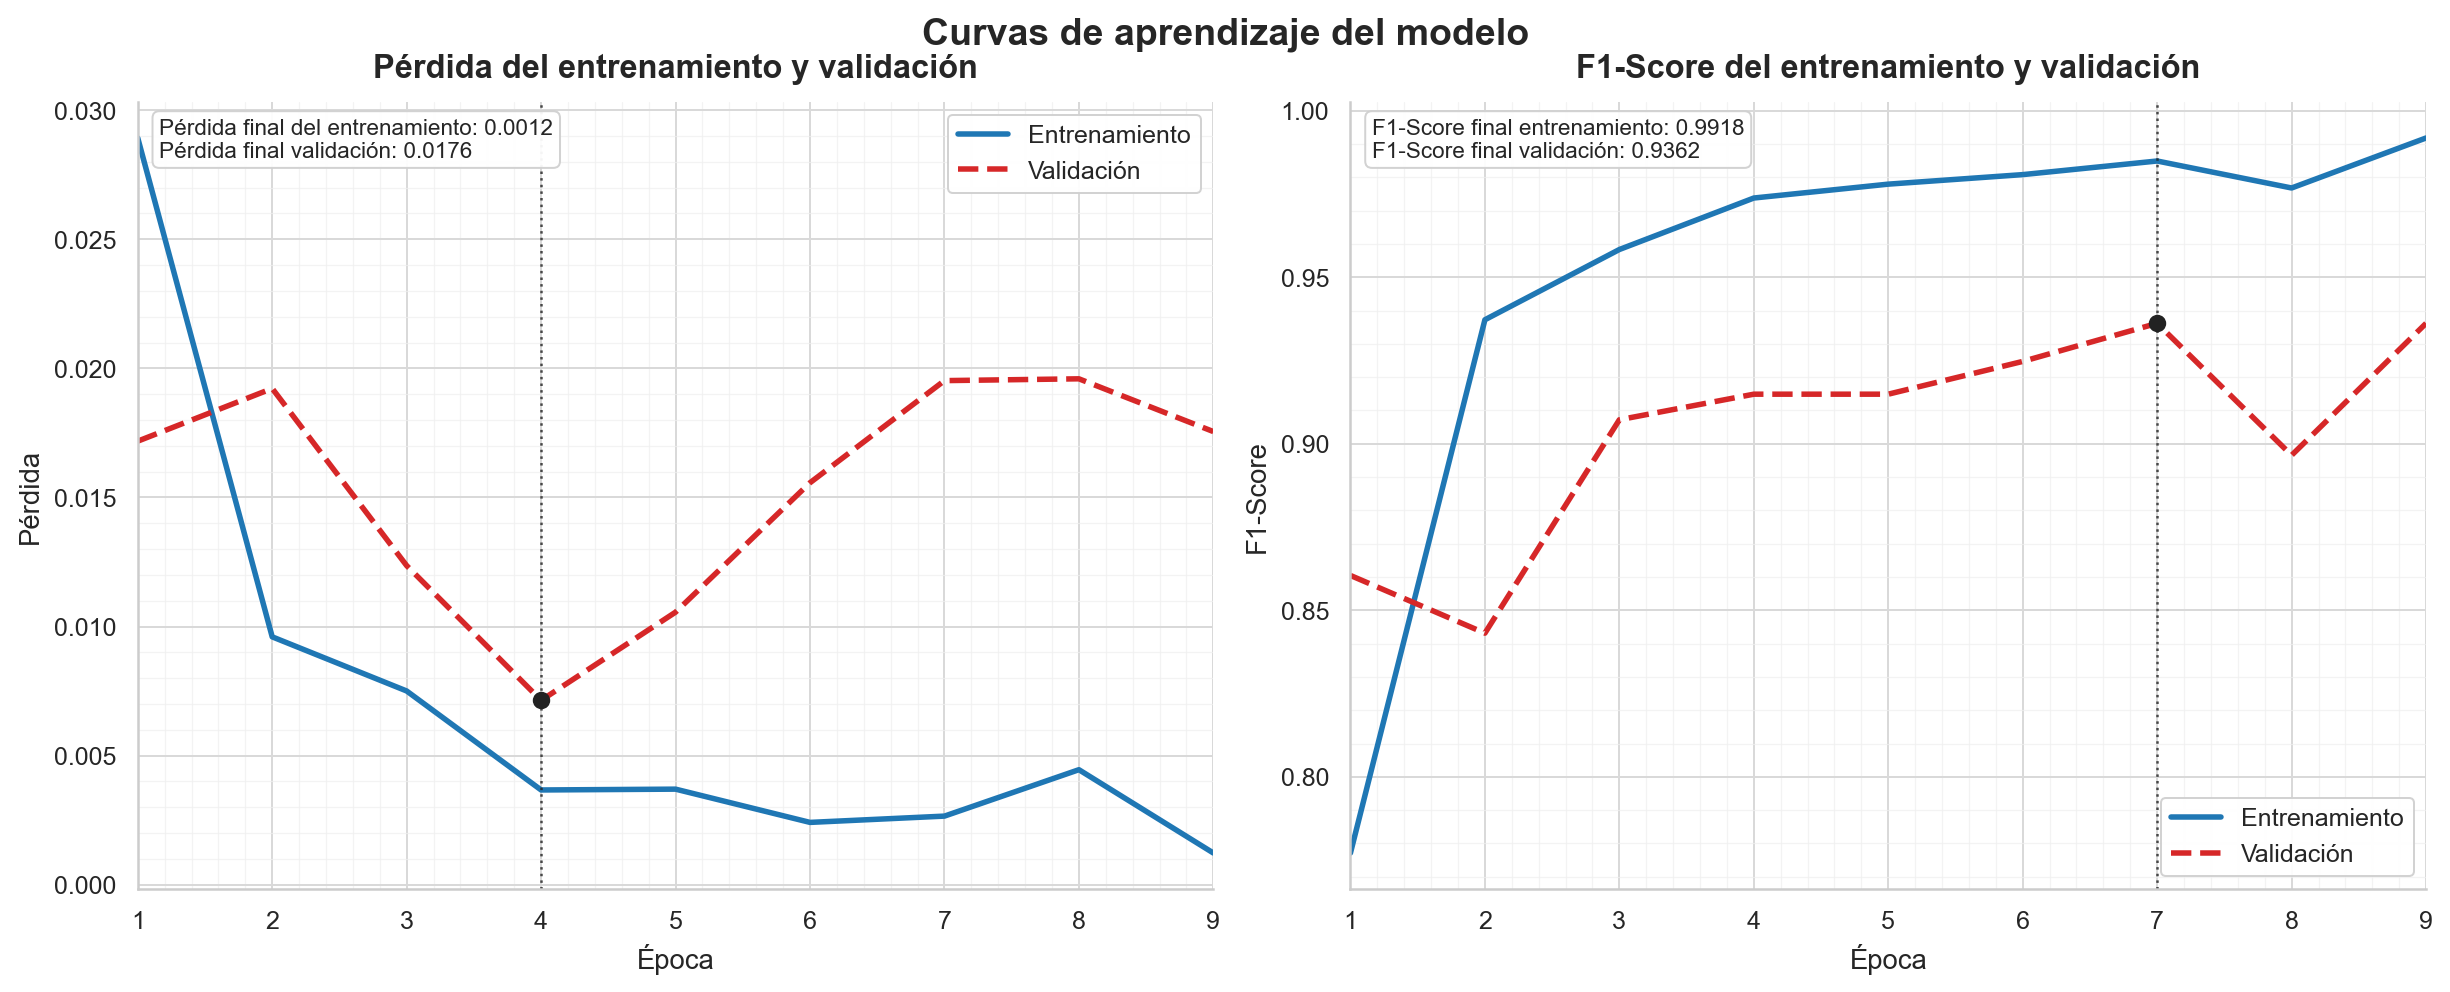

In [19]:
plot_charts(history, ('loss', 'f1_score'), ('Pérdida', 'F1-Score'))